# 01 · 初始项目：天机学堂项目接手与开发环境


## 本章范围与学习路线

天机学堂模拟的是**接手已有微服务项目**：先拉取代码、连通公共开发环境、读懂请求链路，再通过一个订单删除 BUG 熟悉开发、测试和部署流程。本章结束时应能解释一次请求经过哪些组件，并判断问题出在网络、路由、身份传递还是业务判断。

**资料来源**：用户分享的 [AI天机学堂课件](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj) 中的 `day01-初识项目/讲义/day01-初识项目.pptx`（63页），以及 `资料/学习笔记地址.txt` 指向的 [官方 day01 在线讲义](https://my.feishu.cn/wiki/wikcnrigEuKkRaba6YaZubSuINf)。整理日期：2026-10-09。章节按核心概念重组，标注“补充”的代码用于解释，不能视作原仓库源码。

| 顺序 | 要解决的问题 | 完成标志 |
| --- | --- | --- |
| 1 | 项目提供什么业务 | 分清管理端、学员端与各服务职责 |
| 2 | 本地怎样访问公共环境 | 域名解析、Nginx、注册中心和中间件连通 |
| 3 | 该拉取和启动哪些代码 | 从 `lesson-init` 建立开发分支，以 `local` 配置启动负责的服务 |
| 4 | 怎样读懂陌生源码 | 从前端请求找到网关路由、Controller、Service 和数据访问层 |
| 5 | 为什么同一操作有人成功有人失败 | 复现 Jack/Rose 的订单删除差异，解释 Long 比较错误 |
| 6 | 修复怎样到达开发环境 | 完成回归、组件联调，确认 Jenkins 构建和部署的是正确分支 |

> **课件勘误**：PPT 第5页学习目标写了“登录状态刷新”，本章讲义正文和 PPT 第42—62页实际讲解的是**订单删除失败**。本笔记按实际案例展开。Java、YAML、Shell 示例均放在 Markdown 中供阅读与跟练，不在 Python 内核执行。

配套资料还包含 `images/`、`init.sh`（2KB）和 `tjxt.env.tar.gz`（1.33GB）。本笔记基于课件和在线讲义整理，没有解包环境镜像、执行初始化脚本或部署课程系统。


## 项目定位与行业背景

先确定业务对象，才能理解服务为什么这样划分。天机学堂是面向成年人的**非学历职业技能培训平台**，采用 B2C 模式，即平台向个人学员提供课程与学习服务。

| 对象 | 主要任务 | 系统需要支持的能力 |
| --- | --- | --- |
| 学员 | 搜课、买课、学习、提问、考试 | 搜索、交易、支付、课表、学习记录、互动与评测 |
| 老师 | 制作和维护课程、处理教学内容 | 课程分类、媒资、题目、课程审核与发布 |
| 管理员及运营人员 | 维护人员和平台业务 | 用户、权限、订单与营销活动管理 |

讲义把职业教育产业链分为上游的技术、师资和内容支持，中游的教育培训服务，以及下游的就业连接。天机学堂属于中游的非学历技能培训。在线教育允许复用视频与教学资源，也适合分散时间学习，因此业务同时包含电商交易和持续学习。

> **历史背景**：课件市场图覆盖2014—2022年，并引用“双减”政策解释当时的行业变化。它是课程背景材料，不能作为2026年市场规模或增速的依据。


## 两个业务端与支持平台

页面上的功能决定业务边界，业务边界再映射到服务。天机学堂分为学员 PC 网站和后台管理端，两端共享后端能力。

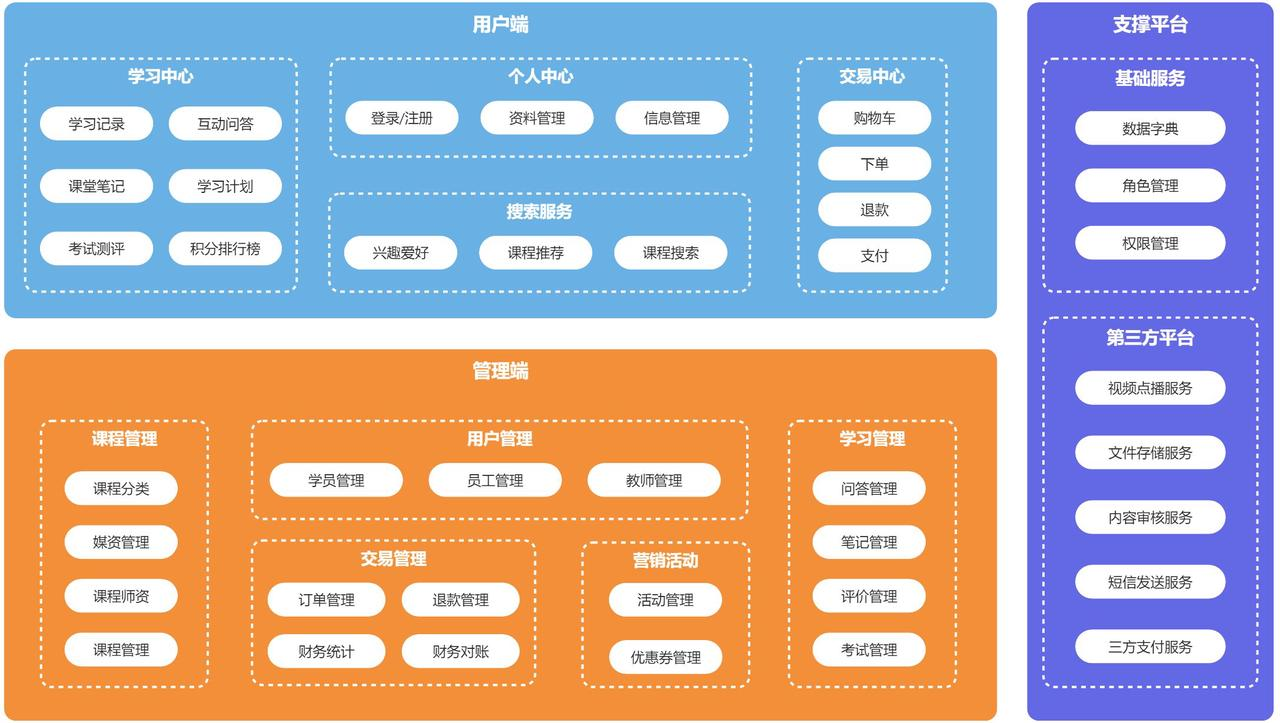

| 业务端 | 核心区域 | 典型业务 |
| --- | --- | --- |
| 学员端 | 学习中心 | 学习记录、互动问答、课堂笔记、学习计划、考试测评、积分排行榜 |
| 学员端 | 个人中心与搜索服务 | 登录注册、资料管理、消息、课程推荐和搜索 |
| 学员端 | 交易中心 | 购物车、下单、支付、退款 |
| 管理端 | 课程与人员管理 | 分类、媒资、题目、课程，以及学员、教师和员工 |
| 管理端 | 交易、营销与学习管理 | 订单、促销，以及问答、笔记等教学业务 |
| 支持平台 | 基础服务及第三方服务 | 数据字典、角色权限，以及视频点播、文件存储等能力 |

老师的主要工作围绕课程内容生产、审核和发布。学员的主要工作围绕买课与学习。后续实现学习功能时，要沿着真实业务事件确认数据来源，例如“已支付订单”如何产生“可学习课程”。


## 核心业务与项目难点

在线教育同时需要处理交易正确性、学习状态和互动数据。PPT 将项目亮点归为三类，它们对应不同的技术问题。

| 领域 | 课件列出的能力 | 开发时要判断什么（补充） |
| --- | --- | --- |
| 电商 | 多支付平台、优惠券、库存超卖、秒杀、超时订单 | 并发请求是否破坏库存和优惠规则，支付结果如何可靠更新订单 |
| 在线学习 | 视频点播、学习辅助、考试评测 | 进度如何记录、重复上报如何处理、谁有学习资格 |
| 社交互动 | 问答、课程评价、通用点赞、积分、排行榜 | 重复点赞、积分发放和榜单统计是否符合业务规则 |

本章先建立项目的运行和交付方式。课程目录中的我的课表、学习计划与进度、并发优化、问答、点赞、积分、排行榜及优惠券，在对应章节继续展开。


## 技术架构与请求分层

技术栈的价值在于它处于请求的哪一层、解决什么问题。先看整体，再定位当前要排查的组件。

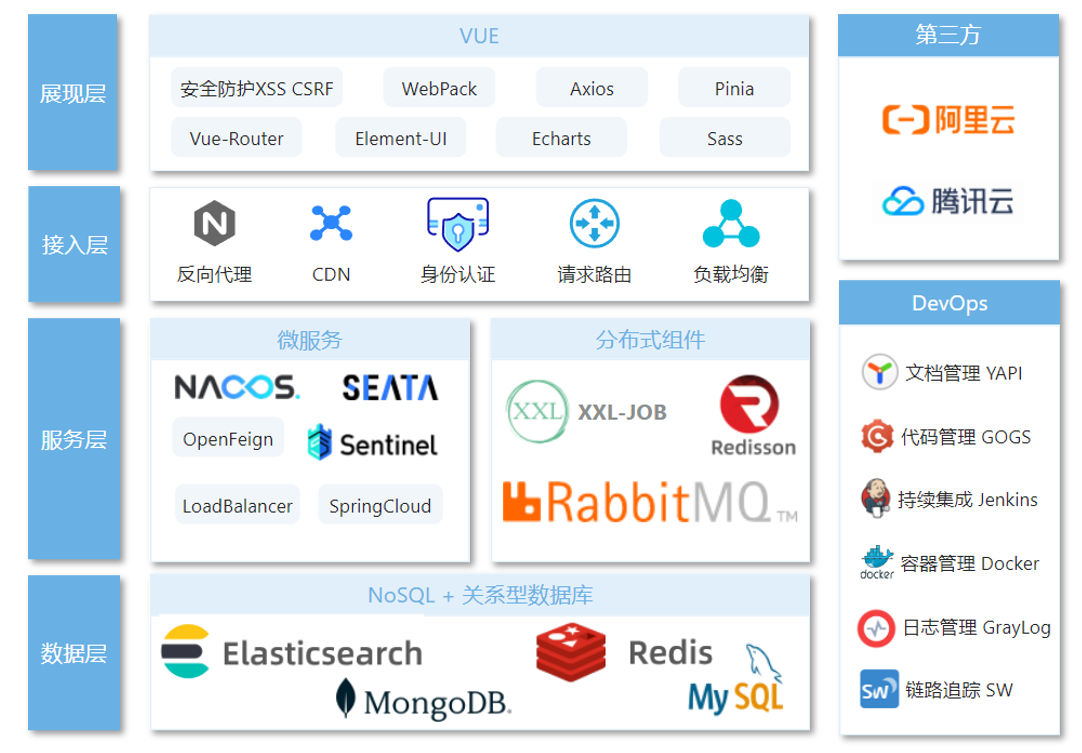

| 层次 | 课程技术 | 职责 |
| --- | --- | --- |
| 展现层 | Vue、Vue Router、Element UI、Axios、Pinia、ECharts、Sass、Webpack | 页面展示、状态管理与接口请求 |
| 接入层 | Nginx、CDN、身份认证、路由、负载均衡 | 静态资源与反向代理，统一入口和请求转发 |
| 微服务 | Spring Cloud、Nacos、OpenFeign、LoadBalancer、Sentinel、Seata | 服务发现、服务调用、流量保护、分布式事务 |
| 分布式组件 | RabbitMQ、Redisson、XXL-Job | 异步消息、Redis相关分布式能力、任务调度 |
| 数据层 | MySQL、Redis、Elasticsearch、MongoDB | 关系数据、缓存、检索及文档数据 |
| 工程交付 | YApi、Gogs、Jenkins、Docker、Graylog、SkyWalking | 接口协作、版本管理、构建部署、日志和链路追踪 |
| 第三方 | 阿里云、腾讯云 | 课程架构中的外部云服务 |

```text
浏览器
  │ 域名解析获得服务器地址
  ▼
Nginx：根据域名和路径反向代理
  ▼
网关：认证、路由，按规则选择微服务
  ▼
微服务：Controller 接收请求，Service 执行业务
  ├─ Mapper / MyBatis-Plus → MySQL
  ├─ OpenFeign → 其他微服务
  └─ Redis / RabbitMQ 等中间件
```

**补充**：注册中心维护可用服务实例，配置中心管理运行参数。Nacos 可以同时承担这两个角色，但“服务已注册”和“配置已正确加载”是两项独立检查。


## 微服务职责与课程起始状态

接手项目时要分清公共模块、已经部署的服务和自己负责的业务。PPT 第20页给出的起始状态如下。状态属于课程初始化版本，不代表后续完成版本。

| 模块 | 职责 | 原课件状态 |
| --- | --- | --- |
| `tj-parent` | 父工程与依赖管理 | √ |
| `tj-common` | 通用工程 | √ |
| `tj-message` | 消息中心 | √ |
| `tj-gateway` | 网关 | √ |
| `tj-auth` | 权限与认证服务 | √ |
| `tj-user` | 用户服务 | √ |
| `tj-pay` | 支付服务 | √ |
| `tj-course` | 课程服务 | √ |
| `tj-exam` | 考试服务 | O |
| `tj-search` | 搜索服务 | √ |
| `tj-trade` | 交易服务 | O |
| `tj-learning` | 学习服务 | X |
| `tj-promotion` | 促销服务 | X |
| `tj-media` | 媒资服务 | √ |
| `tj-data` | 数据服务 | O |
| `tj-remark` | 评价服务 | X |

表中保留课件的 √、O、X。结合后续内容可以理解为已提供、部分待完善、待开发，不用这些符号推断每个接口都已可用。订单删除案例位于 `tj-trade`，在注册与路由配置中使用的服务名是 `trade-service`。

> **补充**：Maven 模块名、目录名和 `spring.application.name` 可以不同。查网关路由和 Nacos 实例时，应使用配置中的服务名。


## 企业开发模式与公共环境

微服务数量多，开发人员也按业务分组。单台电脑可能无法运行全部服务，开发者也未必有全部仓库权限。因此课程采用**本地负责的服务 + 公共开发环境**。

| 位置 | 运行内容 | 使用目的 |
| --- | --- | --- |
| 本地 | 当前正在修改的微服务 | 快速启动、断点调试、接口测试 |
| 公共开发环境 | 其他团队的微服务、网关、数据库及中间件 | 提供依赖并进行跨服务联调 |
| Mock 环境或测试替身 | 模拟部分依赖的响应 | 在依赖未完成或不稳定时验证本服务逻辑 |

```text
开发者本机                       公共开发环境
┌──────────────────┐           ┌──────────────────────────┐
│ 本次修改：交易服务 │ ────────→ │ 用户、课程、支付等微服务 │
│ 或学习/促销服务   │ ────────→ │ Nacos、MySQL、Redis、MQ  │
└──────────────────┘           └──────────────────────────┘
                网关联调时要能选择本机服务实例
```

本地运行的服务既要能访问虚拟机，也要注册一个公共环境可访问的本机地址。只验证“本机能访问虚拟机”，不足以证明网关能够回调本机服务。


## 测试层次与联调范围

一段代码执行成功，不足以证明业务从页面到数据库都正确。测试范围逐步扩大，能帮助定位失败发生在哪一层。

| 层次 | 验证范围 | 本章示例 |
| --- | --- | --- |
| 单元测试 | 一个方法或较小逻辑单元 | 判断两个用户 ID 是否相等 |
| 接口 / 集成测试 | 本服务接口及其必要依赖 | 本地调用删除订单接口，验证数据和身份校验 |
| 组件测试 | 当前微服务与其他服务共同工作 | 经网关访问本地交易服务 |
| 端到端联调 | 页面、网关、业务服务和数据共同工作 | Rose 登录后从订单页删除自己的订单 |

讲义在不同位置把“集成测试”分别用于接口验证和跨服务交互。实践时先写清**测试包含哪些组件**，比只记名称更可靠。Swagger/Knife4j 页面直接调用本地服务时，并没有覆盖 Nginx 和网关。

**补充**：针对这个 BUG，使用缓存范围内和范围外的 ID 才能证明修复有效。只测试 Jack 的 ID=2，错误代码也可能通过。


## 课程虚拟机与基础组件

为了提供公共开发环境，课程准备了虚拟机和环境数据。在线讲义提供两条搭建路径：导入完整虚拟机，或按“自定义部署”文档使用 Docker Compose、基础数据和初始化脚本。

| 组件 | 作用 | 验证时关注 |
| --- | --- | --- |
| Gogs | Git 私服 | 仓库、分支和访问权限 |
| Jenkins | 持续集成 | Webhook、构建日志与部署任务 |
| Nacos | 注册与配置中心 | 实例地址、命名空间、共享配置 |
| MySQL / Redis | 业务数据库与缓存 | 数据初始化、连接地址和账号 |
| RabbitMQ | 消息中间件 | 服务端口、虚拟主机与消费配置 |
| Seata | 分布式事务 | 事务服务是否可用 |
| XXL-Job | 分布式任务调度 | 调度中心与执行器注册 |
| Elasticsearch / Kibana | 搜索引擎与控制台 | 索引、数据和界面访问 |
| Nginx | 域名入口和反向代理 | server_name 与代理目标 |
| Sentinel / MongoDB | 流量保护、文档数据库 | 按课程实际部署版本检查 |

课程示例虚拟机 IP 为 `192.168.150.101`，后续 hosts、Git 和中间件配置使用同一个地址。跟练前以课程导入说明确认网络、资源和启动步骤，不能仅凭环境压缩包名称推断其中服务已运行。

> **操作勘误**：原讲义建议关闭 Windows 防火墙。排查应先确认路由和端口，再为课程需要的可信网络与端口设置访问规则，避免把关闭整机防火墙作为常规步骤。本笔记未修改网络或防火墙。


## hosts、域名与 Nginx 反向代理

课程域名是本地实验环境的入口。`hosts` 将域名映射到虚拟机 IP，Nginx 再按域名转发到对应服务。**hosts 只能映射 IP，不能指定端口或把域名转到另一条 URL。**

Windows 的 hosts 文件通常位于 `C:\Windows\System32\drivers\etc\hosts`。课程示例：

```text
192.168.150.101 git.tianji.com
192.168.150.101 jenkins.tianji.com
192.168.150.101 mq.tianji.com
192.168.150.101 nacos.tianji.com
192.168.150.101 xxljob.tianji.com
192.168.150.101 es.tianji.com
192.168.150.101 api.tianji.com
192.168.150.101 www.tianji.com
192.168.150.101 manage.tianji.com
192.168.150.101 cpolar.tianji.com
```

| 入口 | 课程用途 | 课件对应的后端端口示例 |
| --- | --- | --- |
| `git.tianji.com` | Gogs 网页与仓库 | Git 克隆示例直连10880 |
| `jenkins.tianji.com` | Jenkins 控制台 | 由 Nginx 配置决定 |
| `nacos.tianji.com` | Nacos 控制台 | 8848 |
| `mq.tianji.com` | RabbitMQ 管理界面 | 15672；消息连接使用5672 |
| `es.tianji.com` | 课件中的 Kibana 界面 | 5601；它不同于 ES 查询接口 |
| `api.tianji.com` | 后端网关入口 | 由网关与代理配置决定 |
| `www.tianji.com` / `manage.tianji.com` | 学员端 / 管理端 | 前端站点 |

```text
浏览器访问 http://nacos.tianji.com
  hosts：nacos.tianji.com → 192.168.150.101
  HTTP：请求送到虚拟机，Host 仍是 nacos.tianji.com
  Nginx：按 Host 选择代理规则 → Nacos:8848
```

**补充排查**：页面打不开时，依次确认映射、虚拟机连通、Nginx入口和后端组件。网页出现502，通常意味着请求到达代理，但代理没有取得有效的上游响应。不要把所有失败都归因于 hosts。


## 持续集成与开发环境部署

多人协作需要让远端环境运行同一份可追踪代码。Gogs 保存源码，Webhook 在推送后通知 Jenkins，Jenkins 拉取指定分支，执行编译和打包，再由部署任务更新 Docker 中的服务。

```text
本地修改并提交
  → push 到 Gogs
  → Webhook 通知 Jenkins
  → 检出配置的分支与提交
  → 编译、打包、构建产物
  → 执行部署任务，更新服务
  → 检查日志与注册状态
  → 页面联调
```

课件已经提供构建、部署脚本和钩子配置。在线讲义同时提到自动编译，以及按需手动部署。使用时应查看实际任务：**构建成功不等于容器已经更新，也不等于新服务可用。**

| 要确认的状态 | 可以查看的证据 |
| --- | --- |
| push 已到达仓库 | 远端分支包含本次提交 |
| 构建使用正确代码 | Jenkins 检出的分支和提交号 |
| 部署使用正确产物 | 部署任务记录、镜像或制品版本 |
| 服务已经启动 | 日志、容器状态、Nacos 实例 |
| 修复确实生效 | 实际页面或接口回归结果 |

课程控制台示例：`http://git.tianji.com`（`tjxt/123321`）与 `http://jenkins.tianji.com`（`root/123`）。这些是课程示例账号，适用于课件环境。


## 拉取代码与初始化开发分支

课程 `master` 提供完整版本，课堂开发从 `lesson-init` 开始，避免直接拿完成版代替跟练过程。PPT 第38页的命令：

```bash
# 在 IDEA 工作空间内执行，课程建议使用不含中文和空格的路径
git clone http://192.168.150.101:10880/tjxt/tianji.git -b lesson-init
cd tianji
git checkout -b dev
```

随后使用 IDEA 打开工程并完成 Maven 导入。

| 分支 | 课程用途 |
| --- | --- |
| `master` | 完整项目代码 |
| `lesson-init` | 初始化代码，作为课堂开发起点 |
| `dev` | 从初始化分支创建的开发分支 |
| 临时修复分支 | 保存单项修改，测试后合并到 `dev` |

资料文本还列出前端仓库 `tj-protal` 和 `tj-admin`，分别对应用户端与管理端。该文本把服务端仓库写成 `tjxt`，正文和 PPT 的克隆路径则是 `tjxt/tianji.git`。跟练以 Gogs 中实际仓库路径为准，区分仓库所属用户或组织和仓库名。

**补充**：导入后先核对项目 JDK、Maven、依赖与启动参数。不要先把课程工程升级到最新依赖版本，否则环境问题和代码问题会混在一起。


## 多模块工程与微服务边界

工程放在同一个仓库中，不代表运行时是一个进程。天机学堂使用一个 Project 管理多个 Module，每个业务微服务仍可独立启动和部署。

| 组织方式 | 特点 | 常见适用情况 |
| --- | --- | --- |
| 每个服务独立 Project / 仓库 | 代码、权限和交付更独立，协作成本较高 | 服务与团队较多的项目 |
| 一个 Project 包含多个 Module | 集中管理依赖和代码，导入较方便 | 本课程采用的方式 |

讲义与 PPT 中的结构可概括为：

```text
tianji / tjxt（Project，名称随资料界面显示）
├─ tj-common                 通用模块
├─ tj-api                    公共 API / 服务调用相关模块
├─ tj-auth
│  ├─ tj-auth-common
│  ├─ tj-auth-service
│  ├─ tj-auth-resource-sdk
│  └─ tj-auth-gateway-sdk
├─ tj-trade                  交易服务
├─ tj-learning               学习服务
├─ tj-promotion              促销服务
└─ 其他服务模块
```

**补充**：公共模块可能只生成被其他模块依赖的库，没有单独启动入口。SDK 是供其他模块接入某项能力的代码包。阅读时先看 `pom.xml` 的依赖和打包方式，再判断一个模块是否需要独立启动。


## DTO、PO、VO 与 Query

同一个“订单”在接口、业务和数据库中所需字段不同。把对象按用途区分，可以避免把数据库全部字段直接暴露给前端。

| 对象 | 定义 | 用在什么位置 | 示例（补充） |
| --- | --- | --- | --- |
| DTO | Data Transfer Object，数据传输对象 | 前端提交数据、服务间请求或返回 | 下单时提交课程 ID 和优惠信息 |
| PO | Persistent Object，持久化对象 | 与数据库表对应 | 订单 ID、所属用户、状态等表字段 |
| VO | View Object，视图对象 | 返回给前端展示 | 订单标题、展示状态和金额 |
| Query | 查询对象 | 封装查询条件 | 页码、时间范围、订单状态 |

```text
前端 DTO / Query
    ↓ 参数校验
Controller → Service → Mapper / PO → 数据库
    ↑ 业务整理并转换
前端收到 VO
```

> **补充**：对象名表达数据用途，不自动保证权限。删除订单时，服务端仍须核验订单所属用户，不能只相信前端提供的用户 ID。查询对象也应限制可选条件和分页大小。


## 构造器依赖注入

Service 需要 Mapper 或其他服务对象时，让 Spring 提供这些依赖。讲义比较了字段、构造器和 setter 注入，项目推荐构造器注入，并用 Lombok 减少样板代码。

下面是说明机制的简化示例：

```java
@Service
@RequiredArgsConstructor
public class OrderService {
    private final OrderMapper orderMapper;
    private final UserClient userClient;
}
```

`@RequiredArgsConstructor` 为未初始化的 `final` 字段以及需要的 `@NonNull` 字段生成构造器。类只有一个构造器时，Spring 可以使用它注入依赖，通常无需额外写 `@Autowired`。

| 方式 | 关注点 |
| --- | --- |
| 字段注入 | 写法短，但依赖不体现在创建对象的入口，普通单元测试较难直接构造 |
| 构造器注入 | 必需依赖明确，可使用 `final`，测试时能直接传入替身 |
| setter 注入 | 适合明确允许后续设置或可选的依赖 |

**补充**：`@RequiredArgsConstructor` 不会为所有普通字段生成参数。如果依赖字段遗漏 `final`，不能指望该注解自动注入它。


## 自定义异常与统一异常处理

业务代码需要区分参数错误、数据库错误、权限错误等原因，并让接口返回一致的状态和信息。课程在 `tj-common` 中定义自定义异常，集中交给 `CommonExceptionAdvice` 处理。

```java
// 原讲义展示的统一处理类入口
@RestControllerAdvice
@Slf4j
public class CommonExceptionAdvice {
    // 例如通过 @ExceptionHandler(DbException.class) 处理数据库异常
}
```

这里保留注解和类名，省略处理方法。实际返回类型、错误码和异常构造参数应以工程实现为准。

| 位置 | 职责 |
| --- | --- |
| 参数校验 | 检查请求字段是否满足格式与取值要求 |
| Service | 在业务规则不满足时抛出项目约定的异常 |
| 全局异常处理器 | 将异常转换为统一的接口响应并记录必要日志 |
| 前端 | 根据 HTTP 状态和响应体反馈业务结果 |

**补充**：不要捕获异常后无条件返回成功，也不要只凭响应体中的一句“失败”定位问题。排查订单删除时，应同时看请求、HTTP 状态、响应内容和业务日志。


## local、dev 与 Nacos 配置

同一份代码在本地和虚拟机上运行，可能需要不同的服务地址。课件把基础配置保留在工程，把共享参数和可能变化的业务配置放在 Nacos。

| 文件或位置 | 课程职责 |
| --- | --- |
| `bootstrap.yml` | 服务名、端口、日志等基础参数，以及共享配置引用 |
| `bootstrap-dev.yml` | 虚拟机中的开发环境配置 |
| `bootstrap-local.yml` | 本机开发、测试时使用的配置 |
| Nacos 共享配置 | Spring、MyBatis、Redis、MQ、Feign、任务及日志等公共配置 |
| Nacos 服务专用配置 | 当前服务需要独立维护的参数 |

本地启动时在 IDEA 中设置 Active profiles 为 `local`，或使用如下参数（补充示例）：

```text
--spring.profiles.active=local
```

PPT要求本地用 `local`、虚拟机用 `dev`。官方 bootstrap 截图默认激活了 `dev`，因此要检查启动参数实际覆盖后的环境。

```yaml
# 从原讲义 bootstrap 图中摘出的结构，按实际版本核对 Data ID
server:
  port: 8088
spring:
  application:
    name: trade-service
  cloud:
    nacos:
      config:
        file-extension: yaml
        shared-configs:
          - dataId: shared-spring.yaml
          - dataId: shared-redis.yaml
          - dataId: shared-mybatis.yaml
          - dataId: shared-logs.yaml
          - dataId: shared-feign.yaml
          - dataId: shared-mq.yaml
          - dataId: shared-xxljob.yaml
```

> **版本勘误**：讲义小节标题写 `shared-spring.yml`，bootstrap截图引用 `shared-spring.yaml`。Nacos Data ID 要逐字一致，以实际控制台条目与工程引用为准。`bootstrap` 加载方式也依赖课程 Spring Cloud 版本，迁移到新版本时不能只改文件名。


## 共享 Spring 配置与版本兼容

共享 Spring 配置统一 JSON 行为和部分框架兼容设置。原讲义示例：

```yaml
spring:
  jackson:
    default-property-inclusion: non_null
  main:
    allow-bean-definition-overriding: true
  mvc:
    pathmatch:
      matching-strategy: ant_path_matcher
```

| 参数 | 效果 | 读代码时要判断什么 |
| --- | --- | --- |
| `non_null` | 序列化时忽略值为 null 的字段 | 字段缺失是否影响前端判断 |
| `allow-bean-definition-overriding` | 允许同名 Bean 定义覆盖 | 是否把意外的重复定义掩盖了 |
| `ant_path_matcher` | 使用旧的路径匹配策略 | 是否为课程的 Springfox 与 Boot 2.6 兼容问题所需 |

讲义说明 Springfox 的路径匹配与 Spring Boot 2.6 默认策略不同，可能导致 `documentationPluginsBootstrapper` 启动异常。该配置是对应版本的处理办法，不是所有项目都应启用的通用模板。


## 共享数据库配置与服务数据库

多个服务共享连接配置格式，同时各自确定数据库名称。讲义把连接参数写成 Spring 占位符 `${参数名:默认值}`，服务按需覆盖。

```yaml
mybatis-plus:
  configuration:
    default-enum-type-handler: com.baomidou.mybatisplus.core.handlers.MybatisEnumTypeHandler
  global-config:
    field-strategy: 0
    db-config:
      logic-delete-field: deleted
      id-type: assign_id
spring:
  datasource:
    driver-class-name: com.mysql.cj.jdbc.Driver
    url: jdbc:mysql://${tj.jdbc.host:192.168.150.101}:${tj.jdbc.port:3306}/${tj.jdbc.database}?useUnicode=true&characterEncoding=UTF-8&autoReconnect=true&serverTimezone=Asia/Shanghai
    username: ${tj.jdbc.username:root}
    password: ${tj.jdbc.password:123}
```

| 参数 | 课程默认值 | 作用 |
| --- | --- | --- |
| `tj.jdbc.host` | `192.168.150.101` | 数据库主机 |
| `tj.jdbc.port` | `3306` | 数据库端口 |
| `tj.jdbc.database` | 无 | 当前服务使用的数据库，必须提供 |
| `tj.jdbc.username` | `root` | 数据库账号 |
| `tj.jdbc.password` | `123` | 数据库密码 |

交易服务的覆盖示例：

```yaml
tj:
  jdbc:
    database: tj_trade
```

`deleted` 表示课程约定的逻辑删除字段：记录可能保留在表中，而正常查询将它排除。`assign_id` 是 MyBatis-Plus 的分配 ID 策略，课程说明为雪花算法 ID。枚举处理器负责 Java 枚举与数据库值的转换。

> **版本提示（补充）**：`field-strategy: 0` 和枚举处理器配置依赖 MyBatis-Plus 版本，不能直接作为新版本项目的有效配置保证。逻辑删除还要核对实体注解、数据库字段与实际生成 SQL；页面看不到订单，不等于记录已物理删除。


## 共享 RabbitMQ 配置与消费重试

消息消费者可能因为临时故障处理失败。共享配置统一连接与重试参数，服务根据业务覆盖。

```yaml
spring:
  rabbitmq:
    host: ${tj.mq.host:192.168.150.101}
    port: ${tj.mq.port:5672}
    virtual-host: ${tj.mq.vhost:/tjxt}
    username: ${tj.mq.username:tjxt}
    password: ${tj.mq.password:123321}
    listener:
      simple:
        retry:
          enabled: ${tj.mq.listener.retry.enable:true}
          initial-interval: ${tj.mq.listener.retry.interval:1000ms}
          multiplier: ${tj.mq.listener.retry.multiplier:1}
          max-attempts: ${tj.mq.listener.retry.max-attempts:3}
          stateless: ${tj.mq.listener.retry.stateless:true}
```

`virtual-host` 是 RabbitMQ 内的逻辑隔离空间。`initial-interval` 设置初始等待时间，`multiplier=1` 让重试间隔保持不变。`max-attempts` 是尝试次数上限，通常包含首次调用，因此不要理解成“首次调用后再额外重试3次”。

原讲义建议涉及事务时按需改为有状态重试。**补充**：具体语义还要结合消息确认、事务管理器和所用监听容器确认，不能只改 `stateless` 就认为事务已经可靠。

重试可能让同一消息被处理多次。消费者应确认重复处理不会重复发放积分、重复更新订单等，这称为**幂等性**。重试耗尽后的处理也需要与业务一起设计。


## 共享 Redis、Feign 与 XXL-Job 配置

课程还共享缓存连接池、服务调用连接池和调度执行器配置。它们分别控制不同资源，不能混为“请求并发数”。

```yaml
# shared-redis.yaml
spring:
  redis:
    host: ${tj.redis.host:192.168.150.101}
    password: ${tj.redis.password:123321}
    lettuce:
      pool:
        max-active: ${tj.redis.pool.max-active:8}
        max-idle: ${tj.redis.pool.max-idle:8}
        min-idle: ${tj.redis.pool.min-idle:1}
        max-wait: ${tj.redis.pool.max-wait:300}
```

`max-active` 是连接池最大可用连接数，`max-idle/min-idle` 控制空闲连接，`max-wait` 控制取连接时的等待。时间单位和属性支持情况以课程依赖版本为准。

```yaml
# shared-feign.yaml
feign:
  client:
    config:
      default:
        loggerLevel: BASIC
  httpclient:
    enabled: true
    max-connections: 200
    max-connections-per-route: 50
```

Feign 日志级别 `BASIC` 提供基本请求与响应信息。HTTP连接池有总体上限和每条路由上限。本例使用课程版本的 Feign/HttpClient 配置，在新版本中客户端选择和配置前缀可能变化。

```yaml
# shared-xxljob.yaml
tj:
  xxl-job:
    access-token: tianji
    admin:
      address: http://192.168.150.101:8880/xxl-job-admin
    executor:
      appname: ${spring.application.name}
      log-retention-days: 10
      logPath: job/${spring.application.name}
```

调度中心决定何时触发任务，执行器负责在微服务中运行任务。`appname` 复用服务名。`tj.xxl-job` 是项目约定的自定义配置，要结合项目配置类读取，不能假定仅加入这些 YAML 就完成任务接入。


## 陌生源码的阅读方法

从任意类开始读，容易陷入与当前问题无关的细节。讲义采用四步：找到入口、理清链路、紧跟业务主线、逐步深入。

| 步骤 | 具体操作 | 要得到的结果 |
| --- | --- | --- |
| 找入口 | 与原开发者交流，查接口文档，或查看浏览器 Network | 请求方法、路径、参数和响应 |
| 理链路 | 检查域名代理、网关路由、服务名 | 请求实际进入哪一个服务 |
| 跟主线 | 沿 Controller、Service、Mapper 阅读 | 主要业务步骤与校验条件 |
| 查细节 | 在疑似分支看变量、类型、SQL与日志 | 能解释实际结果的证据 |

订单删除案例的已确认链路：

```text
学员订单页发起删除请求
  api.tianji.com → hosts → 192.168.150.101
  Nginx → 网关
  网关根据 /ts 前缀选择 trade-service
  tj-trade 的删除接口
  校验订单所属用户 → 处理删除
```

**补充**：课件文字确认了 `/ts` 前缀。完整路径、HTTP方法、网关是否去掉前缀，要以 Network、路由配置和 Controller 映射共同核对，不能只凭“删除”二字猜接口。


## 订单删除 BUG 的复现与定位

同样是普通用户删除自己的订单，Jack 成功，Rose 失败。先固定操作和输入，再比较两次请求。

| 用户 | 课程示例登录信息 | 用户 ID | 原始结果 |
| --- | --- | --- | --- |
| Jack | `jack/123` | `2` | 自己的订单可以删除 |
| Rose | `rose/123456` | `129` | 自己的订单删除失败 |

两个用户 ID 来自在线讲义的断点分析。调试发现，代码判断“订单属于当前用户”时对两个 `Long` 使用了 `!=`。Rose 的两个 ID 数值都是129，但对象引用不同，条件错误地把她判成非订单所属用户。

复现与定位顺序：

1. 为两名用户准备可用于删除的订单，记录订单 ID、所属用户和状态。
2. 逐一登录，在 Network 中确认请求和响应，避免拿同一订单反复测试删除。
3. 沿 `/ts` 路由定位交易服务的业务方法。
4. 在所属用户校验处打断点，观察当前用户 ID、订单所属 ID、类型与分支结果。
5. 使用相同数值但不同对象的 ID 验证原因，再修改比较方式。

> **补充**：复现不能通过删除他人的真实订单完成。跟练使用课程测试数据，保留订单状态与所属用户校验。


## Long 的引用比较与数值比较

Java 基本类型和包装类的比较行为不同。`long` 保存数值，`Long` 是对象。**两个 Long 使用 `==` 或 `!=`，比较的是引用身份。**

```java
Long a = Long.valueOf(2L);
Long b = Long.valueOf(2L);
System.out.println(a == b);       // true：valueOf 使用小整数缓存

Long c = Long.valueOf(129L);
Long d = Long.valueOf(129L);
System.out.println(c.equals(d)); // true：数值相同
// 常见 JDK 中 c == d 为 false，不能依赖引用比较判断业务 ID
```

`Long.valueOf` 对 `-128` 到 `127` 范围内的值使用缓存。Jack 的 ID=2 恰好复用了同一对象，掩盖了错误。Rose 的 ID=129 超出该范围，暴露了引用比较问题。

| 比较写法 | 语义 | 使用条件 |
| --- | --- | --- |
| `longA == longB` | 基本类型的数值比较 | 两边都是基本类型 |
| `longObjA == longObjB` | 两个包装对象的引用比较 | 不能用于 ID 数值相等判断 |
| `a.equals(b)` | 比较 Long 的值 | `a` 必须非 null，`b` 应为同类型 |
| `Objects.equals(a, b)` | 支持 null 的对象相等比较 | 两个 null 也会被认为相等 |
| `a.longValue() == b.longValue()` | 显式拆箱后比较数值 | 两边必须非 null |

> **勘误**：课件写缓存范围内“可以用 == 判断”，应理解为解释本次偶然成功。业务代码应始终按值比较，不能依赖数值大小、对象创建方式或缓存。两个包装类型直接比较与包装类型同基本类型比较不同，后者可能触发拆箱。

**使用场景（补充）**：订单所属 ID 校验使用值相等。对数据库中允许为空的可选字段，可使用 `Objects.equals`，但认证与所有权检查需要先拒绝缺失 ID。

**面试提示**：包装类缓存为什么让错误代码通过部分测试？因为值相同且来自缓存时，对象引用也可能相同。要区分引用相等、值相等和拆箱，并说明 null 导致的风险。


## 订单所属用户校验的修复

原讲义要求把 `!=` 改为值比较，同时保留所有权规则。以下是简化示例，变量名与异常类不代表原仓库源码。

```java
// 错误：两边均为 Long
if (orderUserId != currentUserId) {
    throw new IllegalStateException("无权删除该订单");
}

// 补充：先拒绝无效身份，再按值比较
if (currentUserId == null || orderUserId == null
        || !orderUserId.equals(currentUserId)) {
    throw new IllegalStateException("无权删除该订单");
}
```

实际项目应继续使用它约定的业务异常、订单存在性校验、状态约束和删除方式。此次修复只改变相等判断的语义。

| 输入 | 预期 |
| --- | --- |
| 自己的有效订单，ID=2 | 允许按业务规则删除 |
| 自己的有效订单，ID=129 | 同样允许删除 |
| 他人的订单 | 拒绝 |
| 当前用户 ID 缺失 | 拒绝 |
| 订单不存在或所属 ID 异常 | 按项目规则拒绝或处理，不能误判为授权成功 |

**补充**：只换成 `Objects.equals` 但不校验 null，可能让两个缺失 ID 被视为相等。修复身份判断时，要一起检查输入有效性。


## IDEA 远程调试与 JDWP

交易服务在虚拟机中运行时，本地断点无法直接接管它。远程调试通过 JDWP（Java 调试通信协议）把 IDEA 连接到远端 JVM。

| 一侧 | 需要完成的配置 |
| --- | --- |
| 远端 JVM | 启用调试代理并监听端口 |
| 容器与主机网络 | 将调试端口映射并允许可信调试客户端连接 |
| IDEA | 创建 Remote JVM Debug，填写主机、端口和调试模式 |
| 本地源码 | 与远端部署版本一致，否则断点与行号可能对不上 |

课件使用 `5005`。推荐把 JVM 参数放在 `-jar` 前面，写成：

```bash
java -agentlib:jdwp=transport=dt_socket,server=y,suspend=n,address=*:5005 -jar tj-trade.jar
```

| 参数 | 含义 |
| --- | --- |
| `transport=dt_socket` | 使用套接字通信 |
| `server=y` | JVM 监听，IDEA作为客户端连接 |
| `suspend=n` | 无需等待调试器即可启动 |
| `address=*:5005` | 支持此语法的 JDK 上监听所有接口的5005端口 |

课程已经提供 Jenkins 调试部署脚本。按课程任务部署后确认 `tj-trade` 对外映射了调试端口，IDEA连接成功，再从页面发起请求进入断点。

> **勘误与补充**：课件把命令写为 `java -jar -agentlib:... xxx.jar`，这里按常规 JVM 命令顺序调整。`*:5005` 的语法依赖 JDK 版本，例如 JDK8 与较新版本的监听语法不同。调试端口允许控制 JVM，只用于可信开发网络。共享服务上长时间停在断点，也会影响其他请求。


## GitFlow 与本次修复分支

分支把单项改动与多人开发进度区分开，方便审核和合并。讲义介绍的 GitFlow：

| 分支 | 来源 | 作用与合并方向 |
| --- | --- | --- |
| Master | 项目主线 | 正式发布版本，接收验证后的发布或修复 |
| Develop | Master | 持续开发主线 |
| Feature | Develop | 开发功能，完成后合并回 Develop |
| Release | Develop | 发布前准备，完成后合并到 Master 和 Develop |
| Hotfix | Master | 紧急修复，完成后合并到 Master 和 Develop |

课程进行了简化：完整 `master` 用于参考，`lesson-init` 作为起点，`dev` 对应开发主线。本章修复分支**从 dev 创建**，与标准 GitFlow 从正式发布主线建 Hotfix 的语义不同。

```bash
# 课程示例，不在当前笔记仓库执行
git checkout dev
git checkout -b hotfix-delete-order-error
# 修改、检查并提交目标文件
git add <本次修改的文件>
git commit -m "fix: compare order owner IDs by value"
git checkout dev
git merge hotfix-delete-order-error
git branch -d hotfix-delete-order-error
git push -u origin dev
```

**补充**：命令中的文件占位符需要换成实际路径。真实团队也可能通过合并请求审查，先按团队流程操作。删除修复分支前要确认改动已合并；这套示例不会替你提交或合并笔记仓库。


## Swagger 接口测试与身份传递

先让修复在本地接口层可验证，再扩大联调范围。课程本地启动交易服务后访问 `http://localhost:8088/doc.html`，找到删除订单接口。

内部微服务通过请求头接收用户信息。讲义在 Swagger 全局参数中加入 `user-info` 请求头，按测试用户填写 ID，再刷新页面进行接口调试。

| 测试条件 | 预期 |
| --- | --- |
| `user-info` 对应订单所属用户 | 满足订单状态规则时删除成功 |
| `user-info` 为另一用户 | 删除失败，数据保持不变 |
| 使用129等缓存范围外的合法 ID | 修复后与小 ID 行为一致 |
| 缺失或非法身份 | 由内部服务约定拒绝，不产生授权绕过 |

```text
页面联调：登录凭证 → 网关认证 → 内部身份头 → 交易服务
本地接口：测试工具手动设置 user-info → 交易服务
```

> **信任边界（补充）**：`user-info` 是课程内部调用约定。直接设置它只适用于受控测试，不能把公网用户自行传入的身份头作为认证结果。生产入口需要清理或覆盖此类内部身份信息，并限制绕过网关的访问。

讲义跳过了本次单元测试，但从回归角度，缓存边界外的 ID 和非本人订单是必须覆盖的条件。验证时同时检查响应与数据库结果，避免只看页面提示。


## 网关到本地服务的组件联调

本机和虚拟机同时注册了交易服务，网关可能选择任意可用实例。若命中旧实例，就会出现“代码改了，但页面仍失败”的现象。

讲义给出的两种办法是停止虚拟机中的交易服务，或在 Nacos 中把虚拟机实例权重设为0，使课程环境中的流量进入本地实例。

| 检查项 | 目的 |
| --- | --- |
| 服务名、命名空间和分组一致 | 网关能够发现本地实例 |
| Nacos 本地实例地址是可达的本机 IP | 虚拟机网关能连接本机，不能注册成仅本机可见的回环地址 |
| 端口与网络规则正确 | 请求可以抵达本机服务 |
| 虚拟机旧实例不再被选中 | 实际访问的是修复代码 |
| 本地日志或断点出现请求 | 提供路由命中的直接证据 |

**补充**：权重为0是否完全排除实例，要结合课程使用的负载均衡实现验证。配置传播和缓存也可能影响切换速度。设置后通过日志或断点确认请求去向，不能只看控制台数字。

共享环境调整会影响其他开发者。实际团队应协调切换，并在联调结束后恢复公共实例状态。本文记录课程方法，没有修改 Nacos 或停止服务。


## Jenkins 分支选择与部署回归

推送修复后仍出现旧 BUG，可能因为 Jenkins 检出的仍是 `lesson-init`。讲义明确要求调整 `tjxt-dev-build` 中的两处配置：

| 配置 | 要确认的内容 |
| --- | --- |
| 触发条件 | 哪个分支的变化允许触发构建，本章应为 `dev` |
| 实际检出分支 | 构建时从哪个分支取代码，本章应为 `dev` |

二者用途不同。“dev 的 push 触发了任务”不保证“任务检出的是 dev”。修改任务后推送 `dev`，核对构建日志中的分支和提交号，再检查部署是否完成。

```text
确认远端 dev 包含修复
  → 检查 Jenkins 触发与检出配置
  → 编译打包成功
  → 部署任务更新交易服务
  → 注册状态正常
  → Jack / Rose 本人订单删除通过
  → 非本人订单删除仍被拒绝
```

**补充**：共享环境已有的错误删除结果不能充当回归数据。每次验证使用新准备的可删除订单，记录提交号、服务实例和测试结果，确保结论可重复。


## 本章排查清单与验收

遇到问题时，先把现象对应到请求链路，收集最靠近失败位置的证据。

| 现象 | 优先检查 |
| --- | --- |
| 课程域名无法访问 | hosts、虚拟机 IP、网络和 Nginx |
| 能进网页但接口502/超时 | Nginx上游、网关实例、目标服务和端口 |
| 服务启动失败 | JDK与依赖、profile、Nacos参数、必填数据库名称 |
| 只有某个用户删除失败 | 用户 ID、Long比较、订单所属用户与业务状态 |
| 断点始终不触发 | 请求命中的实例、远端版本、调试端口与本地源码 |
| Swagger通过但页面失败 | 网关认证、身份传递、路由和目标实例 |
| push以后修复未生效 | 触发分支、检出提交、部署任务与运行版本 |

完成本章后应能：

- 说明学员端、管理端和公共微服务环境的关系。
- 从 `lesson-init` 初始化开发分支，以 `local` 运行目标服务。
- 解释 hosts、Nginx、网关、Nacos各自的作用。
- 分清 DTO、PO、VO、Query，以及基础与共享配置。
- 沿 `/ts` 请求找到交易服务的订单所属用户校验。
- 解释 Jack=2 与 Rose=129 的行为差异，并使用值比较修复。
- 验证正确用户、错误用户和缓存范围外 ID 的结果。
- 确认 Jenkins 构建并部署的是本次修复提交。

本章的开发闭环是：**业务复现 → 请求链路 → 变量与类型 → 修复 → 接口回归 → 组件联调 → 正确版本部署**。
